In [2]:
import numpy as np
import pandas as pd

np.random.seed(42)

NUM_CLIENTS = 5000

# Generazione delle caratteristiche dei clienti
age = np.random.randint(18, 80, NUM_CLIENTS)

tenure = np.random.randint(1, 73, NUM_CLIENTS)

monthly_charges = np.random.uniform(
    25, 120, NUM_CLIENTS
).round(2)

total_charges = (
    tenure * monthly_charges
).round(2)

contract = np.random.choice(
    ["Monthly", "OneYear", "TwoYears"],
    NUM_CLIENTS,
    p=[0.55, 0.25, 0.20]
)

internet_service = np.random.choice(
    ["DSL", "Fiber", "None"],
    NUM_CLIENTS,
    p=[0.35, 0.50, 0.15]
)

payment_method = np.random.choice(
    ["CreditCard", "BankTransfer", "ElectronicCheck"],
    NUM_CLIENTS,
    p=[0.30, 0.35, 0.35]
)

support_calls = np.random.poisson(
    lam=1.5, size=NUM_CLIENTS
)

# Costruzione di un punteggio di rischio
risk_score = (
    -1.5
    + (tenure < 12) * 1.0
    + (tenure < 6) * 0.8
    + (contract == "Monthly") * 1.2
    + (contract == "TwoYears") * (-1.0)
    + (support_calls >= 3) * 1.0
    + (support_calls >= 5) * 0.8
    + (payment_method == "ElectronicCheck") * 0.4
    + (monthly_charges > 90) * 0.4
)

# Conversione del punteggio in probabilità
probability = 1 / (1 + np.exp(-risk_score))

# Generazione della variabile target
churn = np.random.binomial(
    n=1,
    p=probability
)


In [3]:

# Creazione del DataFrame
df = pd.DataFrame({
    "Age": age,
    "Tenure": tenure,
    "MonthlyCharges": monthly_charges,
    "TotalCharges": total_charges,
    "Contract": contract,
    "InternetService": internet_service,
    "PaymentMethod": payment_method,
    "SupportCalls": support_calls,
    "Churn": churn
})

print(df.head())

print("\nDistribuzione Churn:")
print(df["Churn"].value_counts(normalize=True))

   Age  Tenure  MonthlyCharges  TotalCharges Contract InternetService  \
0   56      23          118.51       2725.73  OneYear           Fiber   
1   69      32           61.43       1965.76  Monthly           Fiber   
2   46      62           39.46       2446.52  Monthly             DSL   
3   32      10           88.34        883.40  Monthly           Fiber   
4   60      72           52.01       3744.72  Monthly           Fiber   

     PaymentMethod  SupportCalls  Churn  
0     BankTransfer             0      0  
1  ElectronicCheck             3      0  
2  ElectronicCheck             2      1  
3       CreditCard             1      1  
4     BankTransfer             0      0  

Distribuzione Churn:
Churn
0    0.566
1    0.434
Name: proportion, dtype: float64


In [5]:
X = df.drop("Churn", axis=1)

y = df["Churn"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Test:", X_test.shape)

Training: (4000, 8)
Test: (1000, 8)


In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod"
]

numeric_features = [
    "Age",
    "Tenure",
    "MonthlyCharges",
    "TotalCharges",
    "SupportCalls"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

In [7]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [8]:
from sklearn.pipeline import Pipeline

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", random_forest)
])

# Addestramento
model.fit(X_train, y_train)

print("Addestramento completato!")

Addestramento completato!


In [9]:
# Previsioni sulle osservazioni del test set
y_pred = model.predict(X_test)

# Probabilità di abbandono
y_proba = model.predict_proba(X_test)[:, 1]

print("Prime 10 previsioni:")
print(y_pred[:10])

print("\nPrime 10 probabilità:")
print(y_proba[:10])

Prime 10 previsioni:
[1 1 0 0 1 0 0 1 0 1]

Prime 10 probabilità:
[0.51528802 0.65018909 0.07963689 0.25603122 0.55123714 0.46060606
 0.41498517 0.81011765 0.48479707 0.59768521]


In [10]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("ACCURACY:",
      accuracy_score(y_test, y_pred))

print("PRECISION:",
      precision_score(y_test, y_pred))

print("RECALL:",
      recall_score(y_test, y_pred))

print("F1 SCORE:",
      f1_score(y_test, y_pred))

print("ROC AUC:",
      roc_auc_score(y_test, y_proba))

print("\nCONFUSION MATRIX:")
print(confusion_matrix(y_test, y_pred))

print("\nCLASSIFICATION REPORT:")
print(classification_report(y_test, y_pred))

ACCURACY: 0.654
PRECISION: 0.5808823529411765
RECALL: 0.728110599078341
F1 SCORE: 0.6462167689161554
ROC AUC: 0.7214546253928448

CONFUSION MATRIX:
[[338 228]
 [118 316]]

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0       0.74      0.60      0.66       566
           1       0.58      0.73      0.65       434

    accuracy                           0.65      1000
   macro avg       0.66      0.66      0.65      1000
weighted avg       0.67      0.65      0.65      1000



In [11]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="roc_auc",
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": result.importances_mean,
    "Std": result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

           Feature  Importance       Std
4         Contract    0.119351  0.016457
7     SupportCalls    0.035238  0.007097
1           Tenure    0.016508  0.005077
6    PaymentMethod    0.016283  0.004246
3     TotalCharges    0.011629  0.005366
2   MonthlyCharges    0.004978  0.004491
0              Age    0.004156  0.002520
5  InternetService    0.000623  0.002493


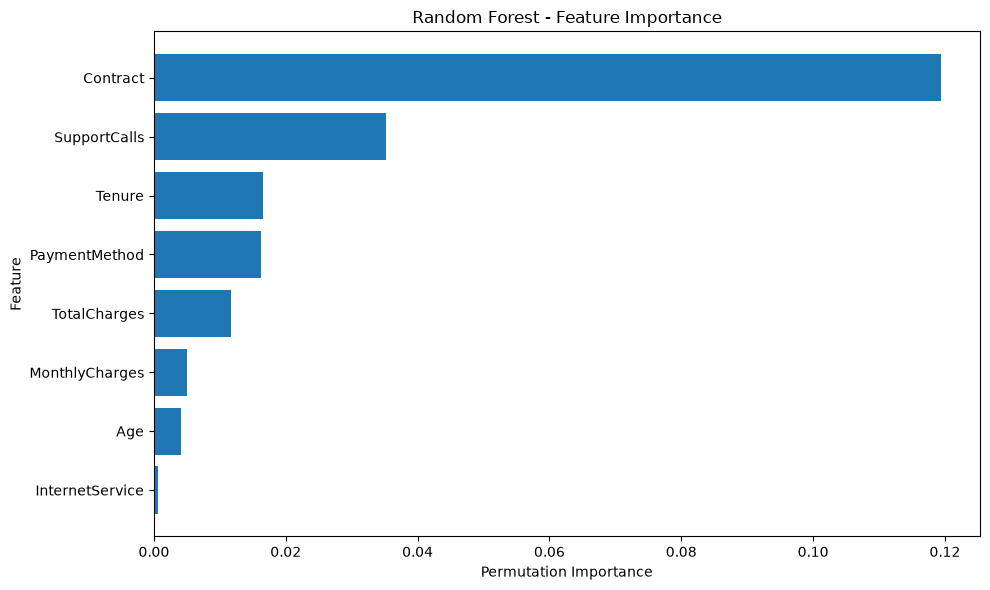

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [ ]:
## Salvataggio del modello addestrato
import joblib

MODEL_PATH = "random_forest_churn.pkl"

joblib.dump(model, MODEL_PATH)

print("Modello salvato:", MODEL_PATH)

In [ ]:
## Ripresa del modello senza dover rifare l'addestramento
import joblib
import pandas as pd

# Caricamento del modello
model = joblib.load("random_forest_churn.pkl")

# Nuovo cliente
new_customer = pd.DataFrame([{
    "Age": 35,
    "Tenure": 4,
    "MonthlyCharges": 95.50,
    "TotalCharges": 382.00,
    "Contract": "Monthly",
    "InternetService": "Fiber",
    "PaymentMethod": "ElectronicCheck",
    "SupportCalls": 5
}])

# Classificazione
prediction = model.predict(new_customer)

# Probabilità
probability = model.predict_proba(new_customer)[0]

churn_probability = probability[1]

print("Classe prevista:", prediction[0])

print(
    "Probabilità di abbandono:",
    f"{churn_probability:.2%}"
)

if prediction[0] == 1:
    print("ATTENZIONE: cliente a rischio abbandono!")
else:
    print("Cliente non classificato come a rischio.")

In [ ]:
## Ottimizzazione degli iperparametri

from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [8, 12, 16, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]
}

grid_search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Migliori parametri:")
print(grid_search.best_params_)

print("\nMigliore ROC AUC:")
print(grid_search.best_score_)

# Modello ottimizzato
best_model = grid_search.best_estimator_

# Salvataggio
joblib.dump(
    best_model,
    "random_forest_churn_optimized.pkl"
)